# Тематическое моделирование текстовых данных

Цель работы:

Выполнить исследование двух текстовых корпусов (коллекции фильмов и публикаций Хабра), провести их предварительную обработку, построить облака слов и выполнить тематическое моделирование с использованием методов TF-IDF и алгоритма кластеризации KMeans.

# Подключение библиотек

In [1]:
import pandas as pd
import numpy as np

import re

import matplotlib.pyplot as plt

from wordcloud import WordCloud

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.cluster import KMeans

import warnings

warnings.filterwarnings('ignore')

# Часть 1. Анализ коллекции фильмов

In [2]:
films = pd.read_csv('top500_films.csv')

films.head()

,title,genre,year,country,rating,description
0,1+1,"драма, комедия",2011,Франция,8.9,"Пострадав в результате несчастного случая, бог..."
1,Джентльмены,"криминал, комедия, боевик",2019,"США, Великобритания",8.7,Один ушлый американец ещё со студенческих лет ...
2,Триггер,драма,2018,Россия,8.5,Психолог Артём Стрелецкий — сторонник шоковой ...
3,Гнев человеческий,"боевик, триллер",2021,"Великобритания, США",7.7,Грузовики лос-анджелесской инкассаторской комп...
4,Брат,"драма, криминал, боевик",1997,Россия,8.4,"Демобилизовавшись, Данила Багров возвращается ..."


In [3]:
films.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 495 entries, 0 to 494
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        495 non-null    object 
 1   genre        495 non-null    object 
 2   year         495 non-null    int64  
 3   country      495 non-null    object 
 4   rating       495 non-null    float64
 5   description  495 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 23.3+ KB


In [4]:
films.isnull().sum()

title          0
genre          0
year           0
country        0
rating         0
description    0
dtype: int64

## Формирование текстового корпуса

In [5]:
films = films.fillna('')

films['document'] = (
    films['title']
    + ' '
    + films['genre']
    + ' '
    + films['description']
)

## Предобработка текста

In [6]:
def preprocess_text(text):

    text = str(text)

    text = text.lower()

    text = re.sub(r'[^a-zа-яё\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text)

    return text.strip()

films['document'] = films['document'].apply(preprocess_text)

films.head()

,title,genre,year,country,rating,description,document
0,1+1,"драма, комедия",2011,Франция,8.9,"Пострадав в результате несчастного случая, бог...",драма комедия пострадав в результате несчастно...
1,Джентльмены,"криминал, комедия, боевик",2019,"США, Великобритания",8.7,Один ушлый американец ещё со студенческих лет ...,джентльмены криминал комедия боевик один ушлый...
2,Триггер,драма,2018,Россия,8.5,Психолог Артём Стрелецкий — сторонник шоковой ...,триггер драма психолог артём стрелецкий сторон...
3,Гнев человеческий,"боевик, триллер",2021,"Великобритания, США",7.7,Грузовики лос-анджелесской инкассаторской комп...,гнев человеческий боевик триллер грузовики лос...
4,Брат,"драма, криминал, боевик",1997,Россия,8.4,"Демобилизовавшись, Данила Багров возвращается ...",брат драма криминал боевик демобилизовавшись д...


## Облако слов для фильмов

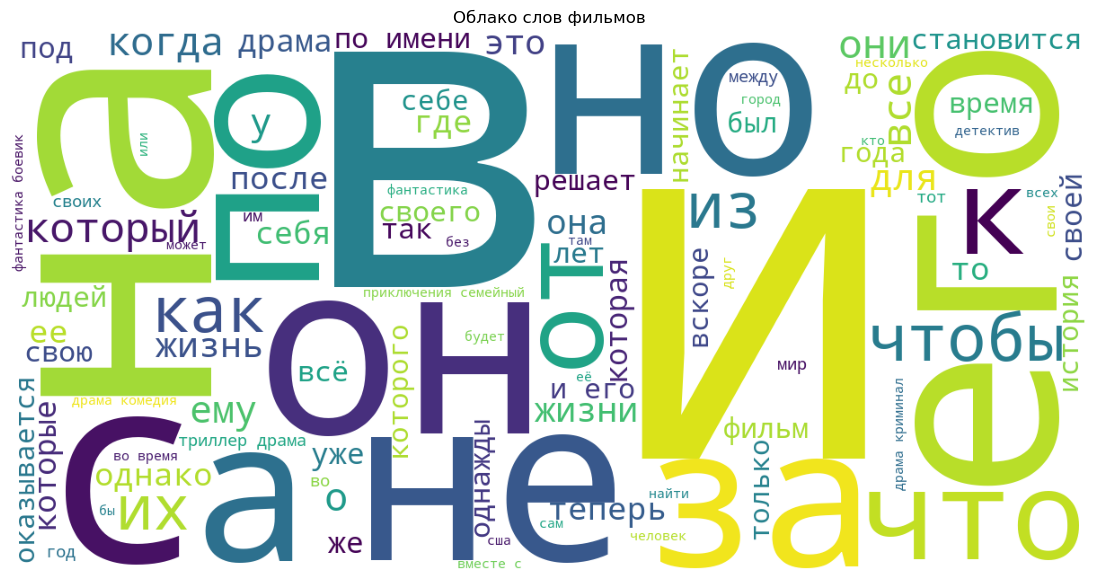

In [7]:
text_data = ' '.join(films['document'])

cloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100
)

cloud.generate(text_data)

plt.figure(figsize=(14,7))

plt.imshow(cloud)

plt.axis('off')

plt.title('Облако слов фильмов')

plt.show()

## TF-IDF векторизация

In [8]:
tfidf_model = TfidfVectorizer(
    max_features=4000,
    stop_words='english'
)

films_vectors = tfidf_model.fit_transform(
    films['document']
)

print(films_vectors.shape)

(495, 4000)


## Кластеризация методом KMeans

In [9]:
cluster_model = KMeans(
    n_clusters=6,
    random_state=42
)

films['cluster'] = cluster_model.fit_predict(
    films_vectors
)

In [10]:
films[['title', 'cluster']].head(15)

,title,cluster
0,1+1,1
1,Джентльмены,3
2,Триггер,0
3,Гнев человеческий,0
4,Брат,0
5,Волк с Уолл-стрит,4
6,Фишер,3
7,Игра престолов,0
8,Достать ножи,3
9,Телохранители,5


In [11]:
films['cluster'].value_counts().sort_index()

cluster
0     81
1     80
2     31
3    128
4    106
5     69
Name: count, dtype: int64

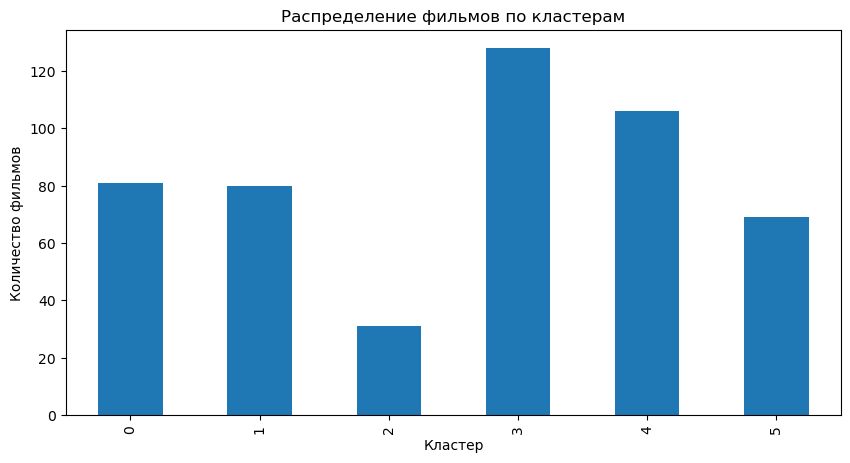

In [12]:
plt.figure(figsize=(10,5))

films['cluster'].value_counts().sort_index().plot(
    kind='bar'
)

plt.xlabel('Кластер')

plt.ylabel('Количество фильмов')

plt.title('Распределение фильмов по кластерам')

plt.show()

## Примеры фильмов внутри кластеров

In [13]:
for cluster_number in range(6):

    print(f'\nКластер {cluster_number}')

    display(
        films[
            films['cluster'] == cluster_number
        ][['title', 'genre']].head(5)
    )


Кластер 0


,title,genre
2,Триггер,драма
3,Гнев человеческий,"боевик, триллер"
4,Брат,"драма, криминал, боевик"
7,Игра престолов,"фэнтези, драма, боевик, мелодрама, приключения"
19,Иван Васильевич меняет профессию,"комедия, фантастика, приключения"



Кластер 1


,title,genre
0,1+1,"драма, комедия"
33,Интерстеллар,"фантастика, драма, приключения"
34,Метод,"триллер, криминал, драма"
38,Зверополис,"мультфильм, комедия, детектив, приключения, се..."
44,Постучись в мою дверь,"мелодрама, комедия"



Кластер 2


...

,title,genre
1,Джентльмены,"криминал, комедия, боевик"
6,Фишер,"детектив, драма, криминал, триллер"
8,Достать ножи,"детектив, комедия, драма, криминал"
10,Зеленая книга,"биография, комедия, драма"
12,Остров проклятых,"триллер, детектив, драма"



Кластер 4


,title,genre
5,Волк с Уолл-стрит,"драма, криминал, биография, комедия"
14,Камбэк,"драма, триллер"
17,Папины дочки. Новые,комедия
18,Один дома,"комедия, семейный"
23,Переводчик,"боевик, триллер, военный, история, драма"



Кластер 5


,title,genre
9,Телохранители,комедия
15,По щучьему велению,"фэнтези, приключения, семейный"
16,Батя,"комедия, мелодрама"
25,Легенда,"криминал, триллер, драма"
30,Кракен,"фантастика, приключения, драма, боевик"


# Часть 2. Анализ публикаций Хабра

In [14]:
habr = pd.read_csv('habr.csv')

habr.head()

,Unnamed: 0,title,namecompany,description,rating,field,date,textpub
0,0,Пора переезжать на локальные LLM. Или нет?,OTUS,"Развиваем технологии, обучая их создателей",686.28,"Консалтинг и поддержка, Рекрутинг и HR, Произв...",2026-03-10,"Нет большой разницы в инструментах, когда речь..."
1,1,Meta* приобрела соцсеть Moltbook для AI-агентов,BotHub,Российский Openrouter,452.68,"Веб-разработка, Программное обеспечение, Веб-с...",2026-03-10,Компания Meta* завершила сделку по покупке Mol...
2,2,Samsung представила Galaxy Vibe Code — новый я...,BotHub,Российский Openrouter,452.68,"Веб-разработка, Программное обеспечение, Веб-с...",2026-03-10,Samsung начала внедрять собственный высокоуров...
3,3,Какая нейросеть лидирует в генерации кода сейч...,BotHub,Российский Openrouter,452.68,"Веб-разработка, Программное обеспечение, Веб-с...",2026-03-10,Новые нейросети появляются на свет с пугающей ...
4,4,Grok восхваляет Маска. Claude работает на Pala...,BotHub,Российский Openrouter,452.68,"Веб-разработка, Программное обеспечение, Веб-с...",2026-03-10,"На фоне всей этой каши между Anthropic, Пентаг..."


In [15]:
habr.columns

Index(['Unnamed: 0', 'title', 'namecompany', 'description', 'rating', 'field',
       'date', 'textpub'],
      dtype='object')

In [16]:
habr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   505 non-null    int64  
 1   title        505 non-null    object 
 2   namecompany  505 non-null    object 
 3   description  505 non-null    object 
 4   rating       505 non-null    float64
 5   field        504 non-null    object 
 6   date         505 non-null    object 
 7   textpub      505 non-null    object 
dtypes: float64(1), int64(1), object(6)
memory usage: 31.7+ KB


In [17]:
habr.isnull().sum()

Unnamed: 0     0
title          0
namecompany    0
description    0
rating         0
field          1
date           0
textpub        0
dtype: int64

## Подготовка текстового корпуса

In [19]:
habr = habr.fillna('')

habr['document'] = (
    habr['title']
    + ' '
    + habr['textpub']
)

## Очистка текста

In [20]:
habr['document'] = habr['document'].apply(
    preprocess_text
)

habr.head()

,Unnamed: 0,title,namecompany,description,rating,field,date,textpub,document
0,0,Пора переезжать на локальные LLM. Или нет?,OTUS,"Развиваем технологии, обучая их создателей",686.28,"Консалтинг и поддержка, Рекрутинг и HR, Произв...",2026-03-10,"Нет большой разницы в инструментах, когда речь...",пора переезжать на локальные llm или нет нет б...
1,1,Meta* приобрела соцсеть Moltbook для AI-агентов,BotHub,Российский Openrouter,452.68,"Веб-разработка, Программное обеспечение, Веб-с...",2026-03-10,Компания Meta* завершила сделку по покупке Mol...,meta приобрела соцсеть moltbook для ai агентов...
2,2,Samsung представила Galaxy Vibe Code — новый я...,BotHub,Российский Openrouter,452.68,"Веб-разработка, Программное обеспечение, Веб-с...",2026-03-10,Samsung начала внедрять собственный высокоуров...,samsung представила galaxy vibe code новый язы...
3,3,Какая нейросеть лидирует в генерации кода сейч...,BotHub,Российский Openrouter,452.68,"Веб-разработка, Программное обеспечение, Веб-с...",2026-03-10,Новые нейросети появляются на свет с пугающей ...,какая нейросеть лидирует в генерации кода сейч...
4,4,Grok восхваляет Маска. Claude работает на Pala...,BotHub,Российский Openrouter,452.68,"Веб-разработка, Программное обеспечение, Веб-с...",2026-03-10,"На фоне всей этой каши между Anthropic, Пентаг...",grok восхваляет маска claude работает на palan...


## Облако слов публикаций Хабра

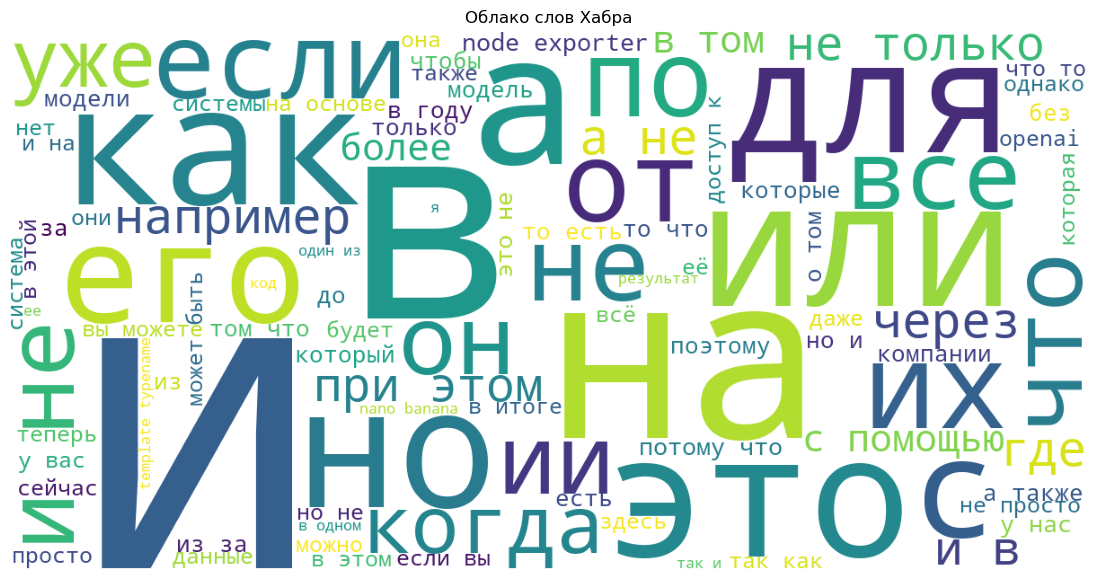

In [21]:
habr_text = ' '.join(
    habr['document']
)

habr_cloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100
)

habr_cloud.generate(habr_text)

plt.figure(figsize=(14,7))

plt.imshow(habr_cloud)

plt.axis('off')

plt.title('Облако слов Хабра')

plt.show()

## TF-IDF представление данных

In [22]:
habr_vectorizer = TfidfVectorizer(
    max_features=4000,
    stop_words='english'
)

habr_vectors = habr_vectorizer.fit_transform(
    habr['document']
)

print(habr_vectors.shape)

(505, 4000)


## Кластеризация публикаций методом KMeans

In [23]:
habr_model = KMeans(
    n_clusters=5,
    random_state=42
)

habr['cluster'] = habr_model.fit_predict(
    habr_vectors
)

In [24]:
habr['cluster'].value_counts().sort_index()

cluster
0      4
1    299
2    118
3     64
4     20
Name: count, dtype: int64

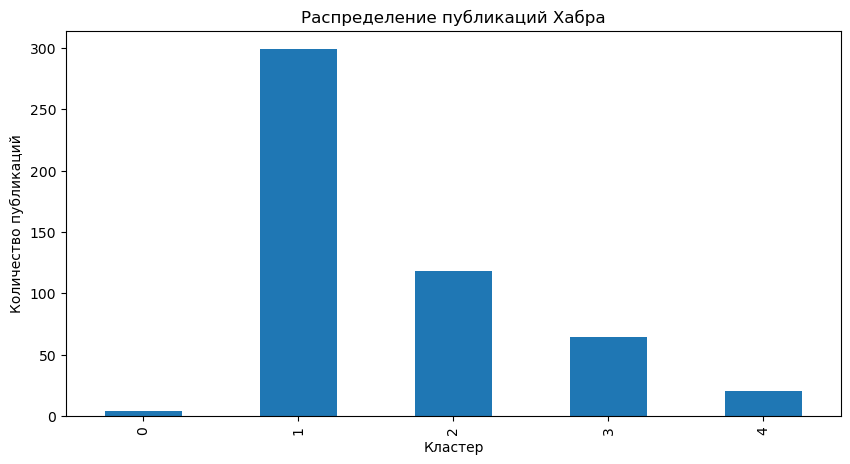

In [25]:
plt.figure(figsize=(10,5))

habr['cluster'].value_counts().sort_index().plot(
    kind='bar'
)

plt.xlabel('Кластер')

plt.ylabel('Количество публикаций')

plt.title('Распределение публикаций Хабра')

plt.show()

## Примеры публикаций внутри кластеров

In [26]:
for cluster_number in range(5):

    print(f'\nКластер {cluster_number}')

    display(
        habr[
            habr['cluster'] == cluster_number
        ][['title']].head(5)
    )


Кластер 0


,title
36,Ушел из жизни создатель HamClock — все устройс...
79,Ушел из жизни создатель HamClock — все устройс...
189,Ушел из жизни создатель HamClock — все устройс...
254,Ушел из жизни создатель HamClock — все устройс...



Кластер 1


,title
3,Какая нейросеть лидирует в генерации кода сейч...
4,Grok восхваляет Маска. Claude работает на Pala...
5,Управляемые блокировки в 1С
6,"Четырёхдневка, Opus 4.6 против Кнута и Cursor ..."
10,Новые методы лечения сложных аноректальных сви...



Кластер 2


,title
0,Пора переезжать на локальные LLM. Или нет?
7,"Мышка поселись, денежка водись: Solar appScree..."
13,Контекст‑инжиниринг для coding‑агентов: почему...
15,Как за 22 часа я собрала полноценный UI-протот...
19,Кейс разработки: интеграционная платформа BRAI...



Кластер 3


,title
1,Meta* приобрела соцсеть Moltbook для AI-агентов
2,Samsung представила Galaxy Vibe Code — новый я...
8,Anthropic запустила программу амбассадоров Claude
32,Anthropic подала в суд на Пентагон из-за стату...
35,Как собрать ИИ‑бота для Telegram за час с помо...



Кластер 4


,title
9,Security Week 2611: атаки на мобильные устройс...
31,В фокусе RVD: трендовые уязвимости февраля
33,Anthropic запустила инструмент Code Review для...
52,Security Week 2611: атаки на мобильные устройс...
74,В фокусе RVD: трендовые уязвимости февраля


## Анализ ключевых слов в кластерах фильмов

In [29]:
film_terms = tfidf_model.get_feature_names_out()

for cluster_id in range(6):

    center = cluster_model.cluster_centers_[cluster_id]

    top_indices = center.argsort()[-10:]

    top_words = [

        film_terms[index]

        for index in top_indices

    ]

    print(f'\nКластер {cluster_id}')

    print(', '.join(top_words))


Кластер 0
на, время, жизни, что, драма, от, из, не, он, его

Кластер 1
боевик, фантастика, от, он, из, его, драма, не, что, на

Кластер 2
семейный, мелодрама, городе, она, отношения, его, на, их, парень, комедия

Кластер 3
из, по, драма, триллер, не, криминал, его, за, он, на

Кластер 4
он, приключения, они, семейный, не, на, что, по, но, его

Кластер 5
им, драма, комедия, история, по, но, они, их, не, на


## Облака слов для каждого кластера фильмов

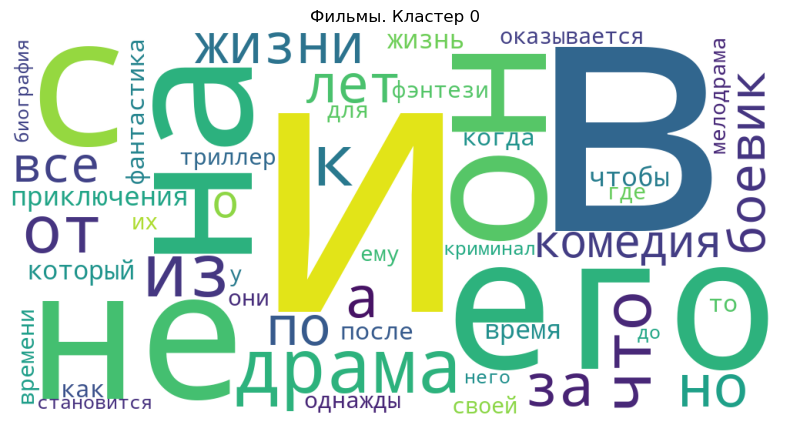

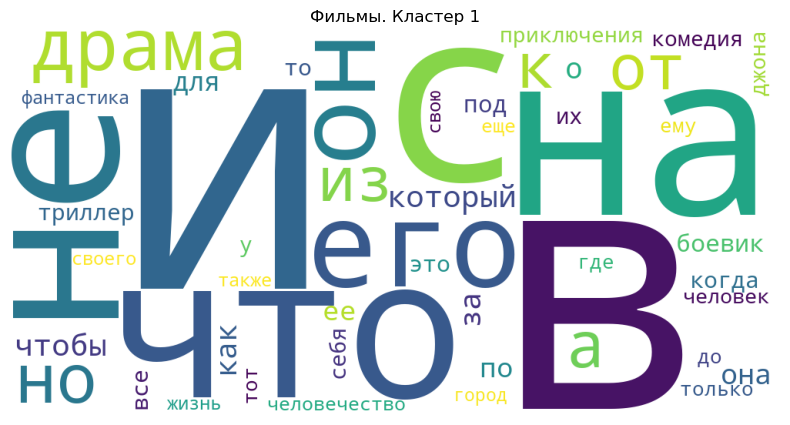

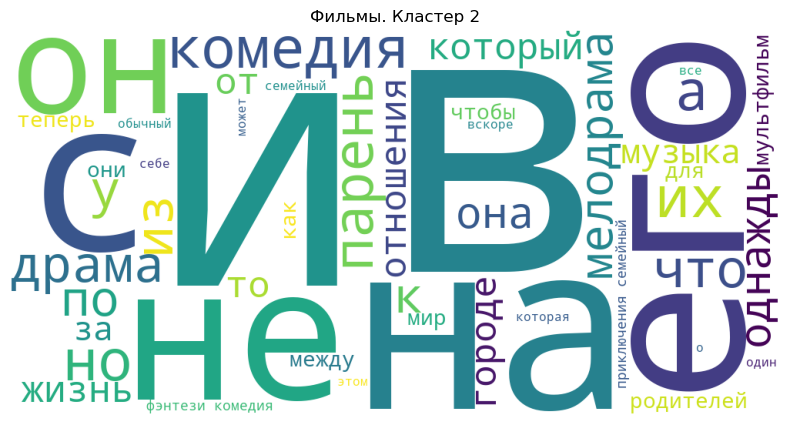

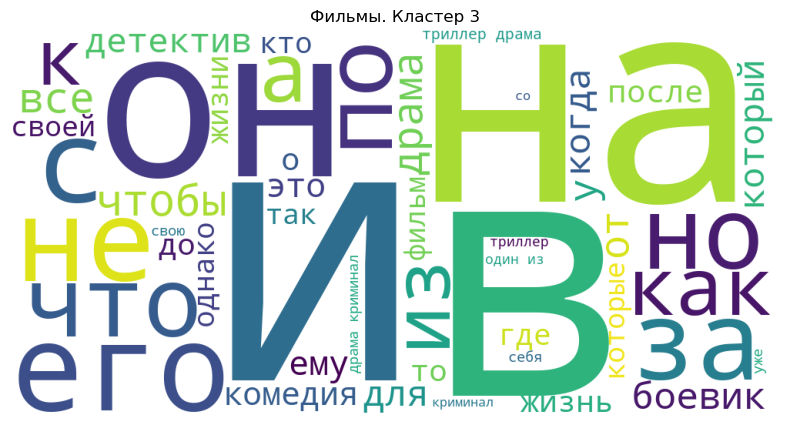

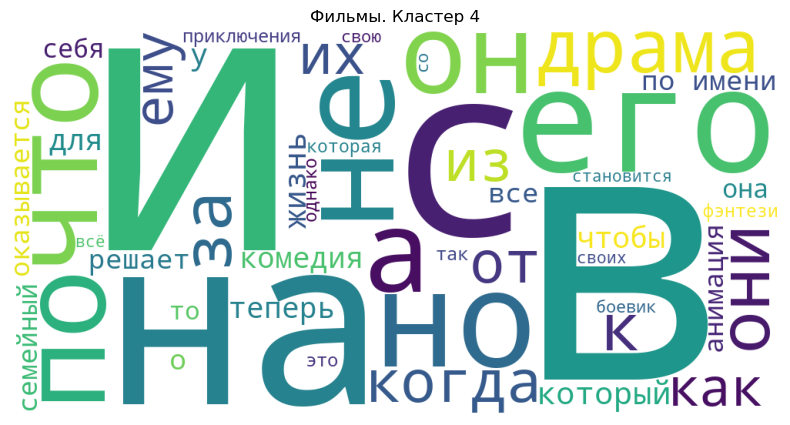

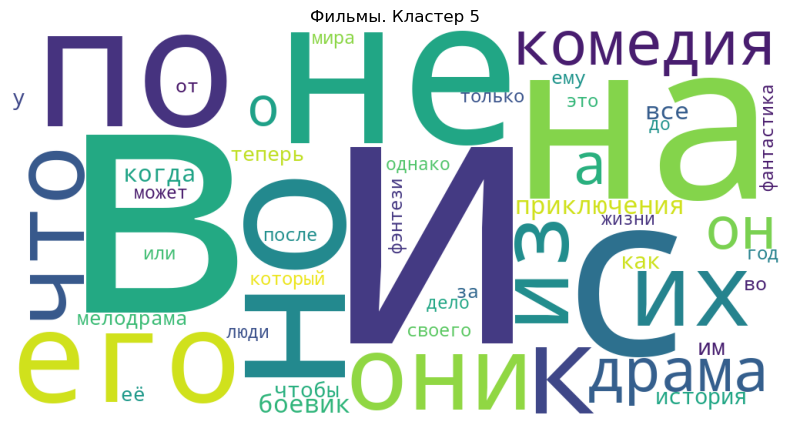

In [30]:
for cluster_id in range(6):

    cluster_text = ' '.join(

        films[

            films['cluster'] == cluster_id

        ]['document']

    )

    cloud = WordCloud(

        width=1000,

        height=500,

        background_color='white',

        max_words=50

    )

    cloud.generate(cluster_text)

    plt.figure(figsize=(12,5))

    plt.imshow(cloud)

    plt.axis('off')

    plt.title(f'Фильмы. Кластер {cluster_id}')

    plt.show()

## Анализ ключевых слов публикаций Хабра

In [31]:
habr_terms = habr_vectorizer.get_feature_names_out()

for cluster_id in range(5):

    center = habr_model.cluster_centers_[cluster_id]

    top_indices = center.argsort()[-10:]

    top_words = [

        habr_terms[index]

        for index in top_indices

    ]

    print(f'\nКластер {cluster_id}')

    print(', '.join(top_words))


Кластер 0
из, отслеживать, для, собственный, исходный, его, wb, сервер, на, hamclock

Кластер 1
то, из, но, по, как, это, что, для, не, на

Кластер 2
или, llm, ai, что, это, как, по, для, не, на

Кластер 3
что, по, задач, moltbook, gpt, openai, ai, на, для, anthropic

Кластер 4
review, касперского, кода, anthropic, code, по, itfb, на, уязвимости, уязвимостей


## Облака слов для каждого кластера Хабра

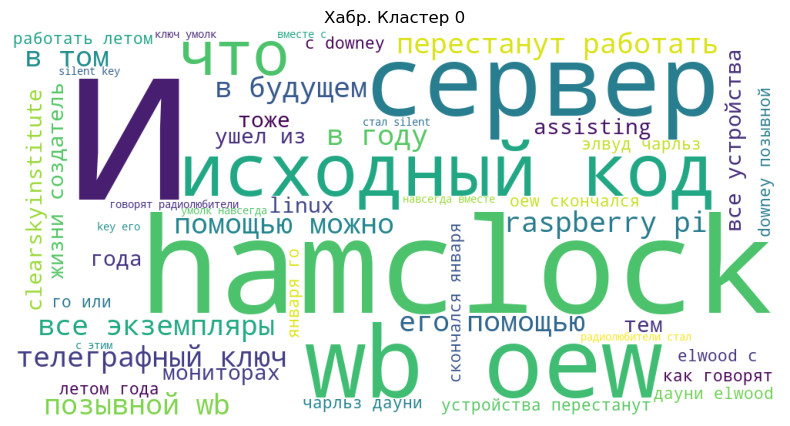

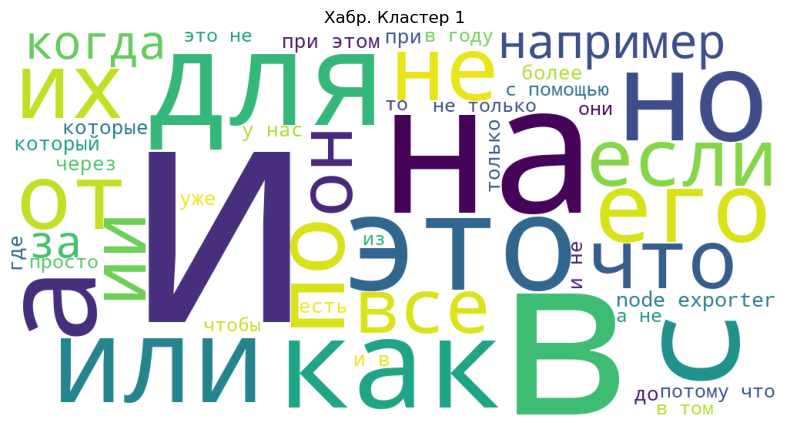

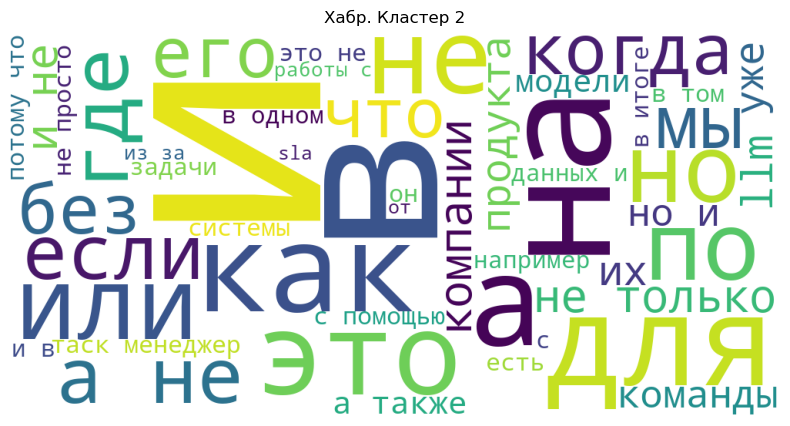

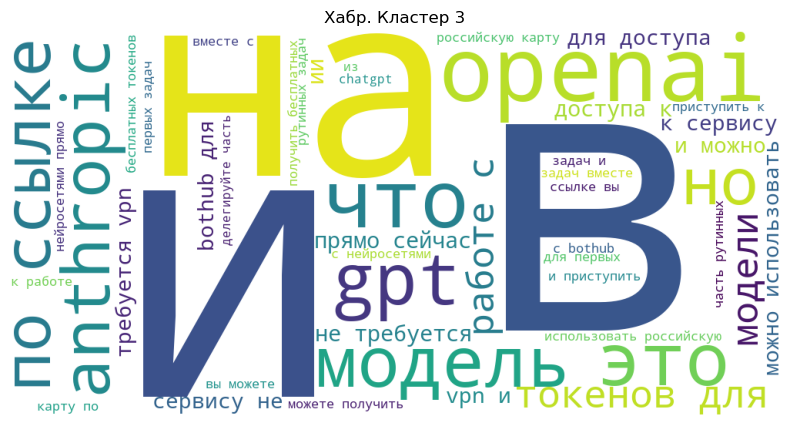

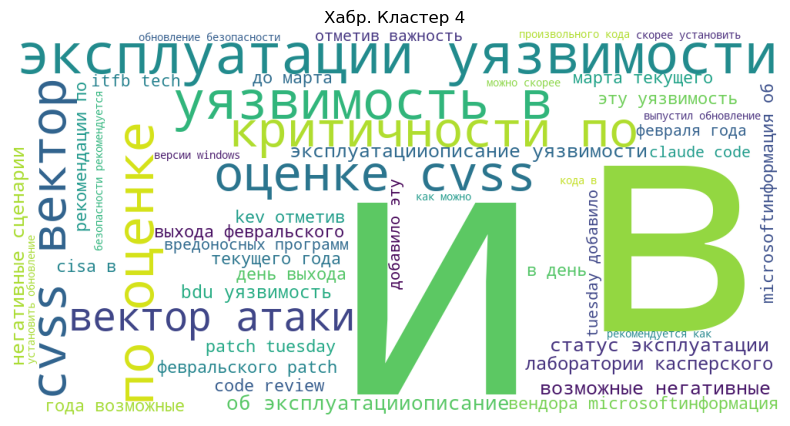

In [32]:
for cluster_id in range(5):

    cluster_text = ' '.join(

        habr[

            habr['cluster'] == cluster_id

        ]['document']

    )

    cloud = WordCloud(

        width=1000,

        height=500,

        background_color='white',

        max_words=50

    )

    cloud.generate(cluster_text)

    plt.figure(figsize=(12,5))

    plt.imshow(cloud)

    plt.axis('off')

    plt.title(f'Хабр. Кластер {cluster_id}')

    plt.show()

## Сравнение размеров исследуемых 

In [33]:
comparison = pd.DataFrame({

    'Набор данных': [

        'Фильмы',

        'Хабр'

    ],

    'Количество документов': [

        len(films),

        len(habr)

    ]

})

comparison

,Набор данных,Количество документов
0,Фильмы,495
1,Хабр,505


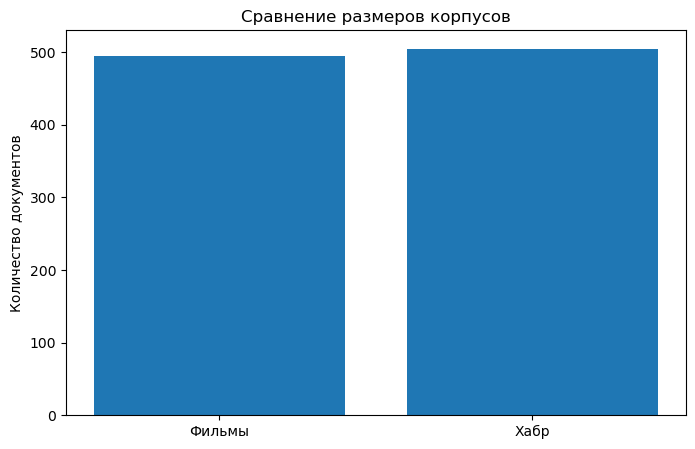

In [34]:
plt.figure(figsize=(8,5))

plt.bar(

    comparison['Набор данных'],

    comparison['Количество документов']

)

plt.title('Сравнение размеров корпусов')

plt.ylabel('Количество документов')

plt.show()

# Вывод

В ходе выполнения работы были исследованы два текстовых корпуса: коллекция фильмов и публикации Хабра.

Для каждого набора данных была выполнена предварительная обработка текста, построены облака слов и сформированы TF-IDF представления документов.

С помощью алгоритма KMeans документы были разделены на тематические группы. Для каждого кластера были определены наиболее значимые слова и выполнен дополнительный анализ полученных результатов.

Проведённое исследование показало возможность автоматического разделения документов на смысловые категории.

Полученные результаты будут использоваться в следующей работе для построения модели классификации и дальнейшей разработки ML-приложения.